# Métodos de la revisión de literatura

Explicaciones **conceptuales** de los métodos que aparecen en los artículos de mi revisión de literatura. El objetivo es tener claro el concepto de cada método, no un tratamiento exhaustivo.

Los métodos están organizados **por función**: cada función es una sección de nivel 1 y cada método una subsección dentro de ella. Cada método se explica como una narrativa corta: para qué sirve → idea central (fórmula y gráfica) → requisitos o limitación principal → aplicación a puentes → tabla de fortalezas y debilidades. El texto está en español; el código, en inglés.

## Tabla de contenido

| Función | Método |
|---|---|
| [1. Descomposición de señales](#descomposicion-de-senales) | [1.1 EMD (Empirical Mode Decomposition)](#emd) |
| [2. Envolvente de amplitud / amplitud instantánea](#envolvente-de-amplitud) | [2.1 Transformada de Hilbert](#transformada-de-hilbert) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, sosfiltfilt, argrelextrema
from scipy.interpolate import CubicSpline
from PyEMD import EMD

# Shared plot style: thin lines, recessive grid, no top/right spines
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e3e2de",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 1.4,
    "legend.frameon": False,
})

# Fixed color roles (same meaning in every plot)
COLOR_SIGNAL = "#8a8984"   # raw / measured signal (neutral gray)
COLOR_1 = "#2a78d6"        # main series (blue)
COLOR_2 = "#eb6834"        # second series (orange)
COLOR_TRUE = "#0b0b0b"     # exact (true) reference curve, dashed

# --- Shared example: vehicle crossing a simply supported bridge ---
L_SPAN = 15.0         # span (m)
V_SPEED = 2.0         # vehicle speed (m/s)
F1, F2 = 5.65, 22.62  # bridge natural frequencies (Hz)
FS = 200.0            # sampling frequency (Hz)

t = np.arange(0, L_SPAN / V_SPEED, 1 / FS)
position = V_SPEED * t                         # vehicle position x = v t (m)
phi_1 = np.sin(np.pi * position / L_SPAN)      # mode 1 shape
phi_2 = np.sin(2 * np.pi * position / L_SPAN)  # mode 2 shape

<a id="descomposicion-de-senales"></a>
# 1. Descomposición de señales

Métodos que separan una señal en componentes más simples, para analizar cada una por separado.

<a id="emd"></a>
## 1.1 EMD (Empirical Mode Decomposition)

### Para qué sirve

Una señal real de un puente mezcla varias frecuencias: varios modos, el vehículo, la rugosidad y el ruido. La EMD la separa en componentes más simples llamadas **IMF** (funciones de modo intrínseco), cada una con aproximadamente **una sola frecuencia dominante**. Es el paso previo para aplicar la transformada de Hilbert ([sección 2.1](#transformada-de-hilbert)), que necesita una sola componente.

### Cómo funciona (sifting)

La EMD extrae las IMF con un proceso llamado **cribado** (*sifting*):

1. Se ubican los máximos locales y se unen con una curva suave (spline cúbico); lo mismo con los mínimos.
2. Se calcula el promedio de las dos envolventes y se le resta a la señal.
3. Se repite hasta que lo que queda oscila de forma pareja alrededor de cero: esa es la primera IMF, la de frecuencia más alta.
4. Se resta esa IMF de la señal y se repite para obtener la siguiente, de frecuencia más baja, hasta que queda un residuo sin oscilaciones.

$$
m(t) = \frac{e_{max}(t) + e_{min}(t)}{2}, \qquad h(t) = x(t) - m(t)
$$

- $x(t)$: señal.
- $e_{max}(t)$ y $e_{min}(t)$: curvas que unen los máximos y los mínimos.
- $m(t)$: su promedio.
- $h(t)$: señal sin ese promedio, candidata a IMF.

En palabras: se le quita a la señal la "línea media" entre sus picos superiores e inferiores.

$$
x(t) = \sum_{i=1}^{n} c_i(t) + r_n(t)
$$

- $c_i(t)$: IMF número $i$.
- $n$: número de IMF.
- $r_n(t)$: residuo.

En palabras: la señal original es la suma de todas las IMF más el residuo.

Se llama **"empírica"** porque no supone funciones base, como los senos de Fourier: las componentes salen de la forma de la propia señal.

Gráfica: un paso del cribado sobre la señal de puente del ejemplo siguiente (modo 1 + modo 2 + ruido pequeño).

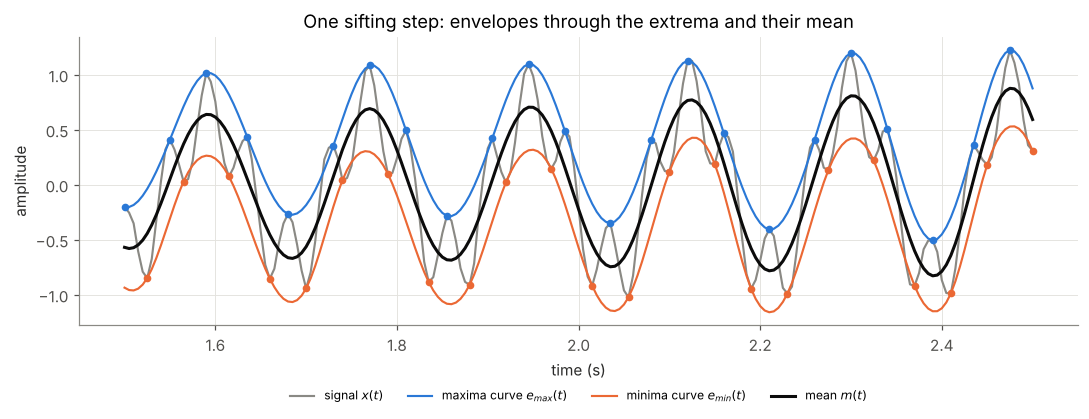

In [2]:
rng = np.random.default_rng(42)   # fixed seed for the noise

# Bridge signal: mode 1 + mode 2 + small noise (also used in the next step)
x_bridge = (phi_1 * np.cos(2 * np.pi * F1 * t)
            + 0.4 * phi_2 * np.cos(2 * np.pi * F2 * t)
            + 0.02 * rng.standard_normal(t.size))

# One sifting step: cubic-spline envelopes through the extrema and their mean
idx_max = argrelextrema(x_bridge, np.greater)[0]
idx_min = argrelextrema(x_bridge, np.less)[0]
upper_envelope = CubicSpline(t[idx_max], x_bridge[idx_max])(t)
lower_envelope = CubicSpline(t[idx_min], x_bridge[idx_min])(t)
mean_envelope = (upper_envelope + lower_envelope) / 2      # m(t)

window = (t >= 1.5) & (t <= 2.5)   # zoom into ~1 s where both modes are strong
in_window = lambda idx: idx[window[idx]]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t[window], x_bridge[window], color=COLOR_SIGNAL, label="signal $x(t)$")
ax.plot(t[window], upper_envelope[window], color=COLOR_1, label="maxima curve $e_{max}(t)$")
ax.plot(t[window], lower_envelope[window], color=COLOR_2, label="minima curve $e_{min}(t)$")
ax.plot(t[window], mean_envelope[window], color=COLOR_TRUE, linewidth=2, label="mean $m(t)$")
ax.plot(t[in_window(idx_max)], x_bridge[in_window(idx_max)], "o", ms=4, color=COLOR_1)
ax.plot(t[in_window(idx_min)], x_bridge[in_window(idx_min)], "o", ms=4, color=COLOR_2)
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("One sifting step: envelopes through the extrema and their mean")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** La media $m(t)$ (negra) sigue la oscilación lenta, el modo 1 (5.65 Hz). Al restarla, $h(t) = x(t) - m(t)$ conserva la oscilación rápida (modo 2): por eso la primera IMF es la de frecuencia más alta.

### Ejemplo: descomponer una señal de puente

Un vehículo cruza un puente de $L = 15$ m a $v = 2$ m/s ($x = vt$). La señal es modo 1, $\sin(\pi x/L)\cos(2\pi f_1 t)$, más modo 2, $0.4\sin(2\pi x/L)\cos(2\pi f_2 t)$, más ruido pequeño. Se aplica la EMD completa con PyEMD.

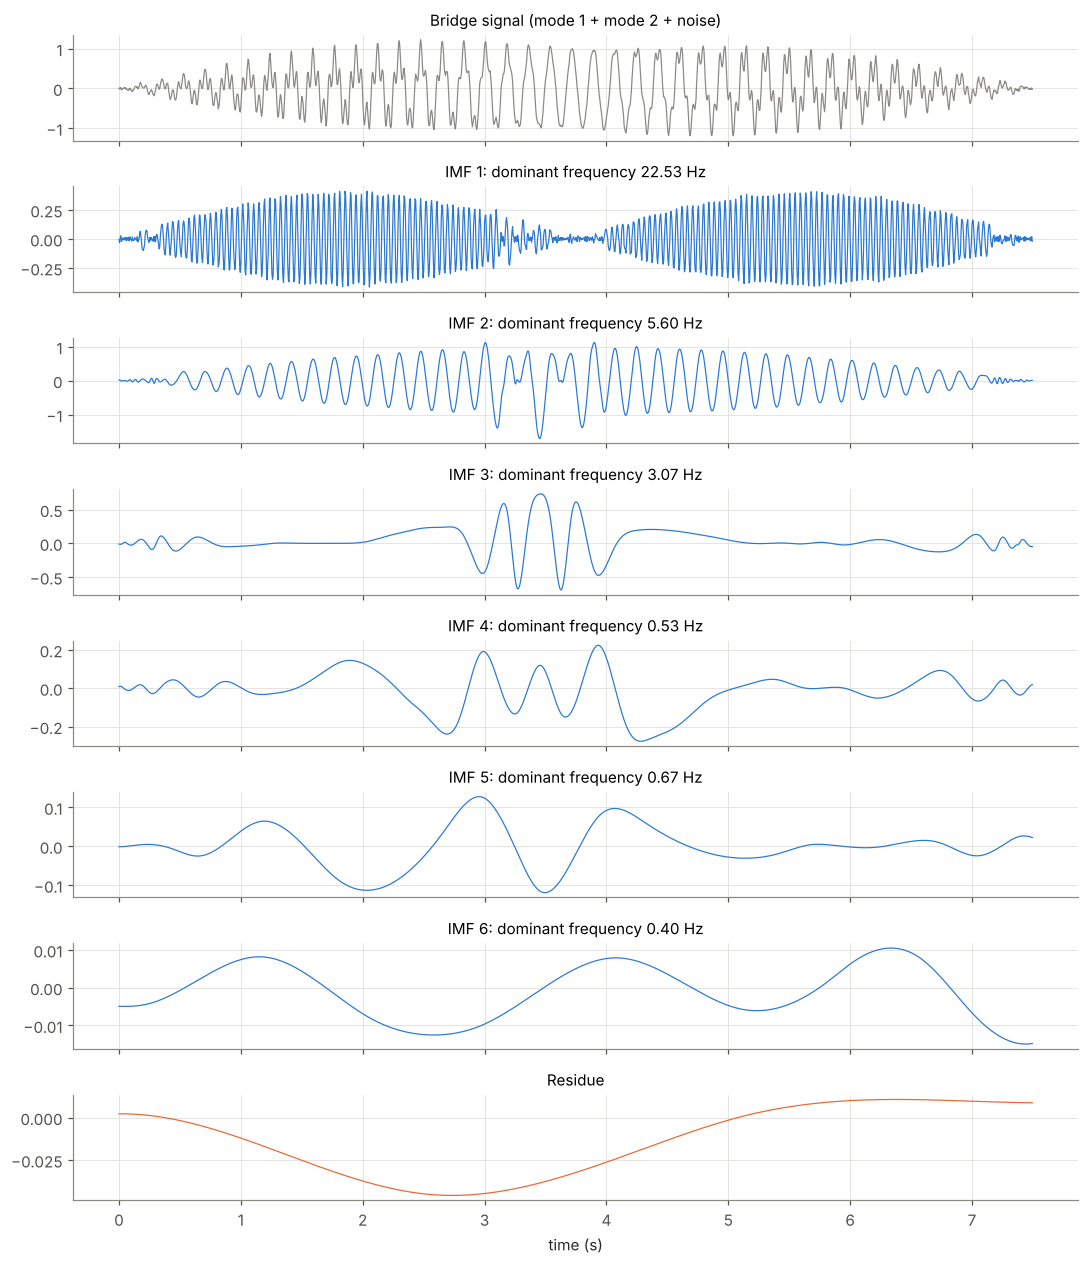

Max reconstruction error |x - (sum of IMFs + residue)|: 0.0e+00


In [3]:
def dominant_frequency(x, fs):
    # Frequency of the largest FFT peak (ignoring 0 Hz)
    spectrum = np.abs(np.fft.rfft(x - x.mean()))
    freqs = np.fft.rfftfreq(x.size, 1 / fs)
    return freqs[np.argmax(spectrum[1:]) + 1]


emd = EMD()
emd.emd(x_bridge, t)
imfs, residue = emd.get_imfs_and_residue()

n_rows = imfs.shape[0] + 2
fig, axes = plt.subplots(n_rows, 1, figsize=(10, 1.45 * n_rows), sharex=True)
axes[0].plot(t, x_bridge, color=COLOR_SIGNAL, linewidth=0.8)
axes[0].set_title("Bridge signal (mode 1 + mode 2 + noise)", fontsize=10)
for i, imf in enumerate(imfs):
    axes[i + 1].plot(t, imf, color=COLOR_1, linewidth=0.8)
    axes[i + 1].set_title(f"IMF {i + 1}: dominant frequency {dominant_frequency(imf, FS):.2f} Hz",
                          fontsize=10)
axes[-1].plot(t, residue, color=COLOR_2, linewidth=0.8)
axes[-1].set_title("Residue", fontsize=10)
axes[-1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

print(f"Max reconstruction error |x - (sum of IMFs + residue)|: "
      f"{np.max(np.abs(x_bridge - imfs.sum(axis=0) - residue)):.1e}")

**Interpretación.**

- **IMF 1 (≈22.6 Hz) = modo 2:** su amplitud dibuja las dos "jorobas" de $\sin(2\pi x/L)$ y se anula a mitad del vano (nodo); ahí y cerca de los apoyos solo queda el ruido.
- **IMF 2 (≈5.6 Hz) = modo 1:** su amplitud crece y decrece como $\sin(\pi x/L)$.
- Cerca de $t \approx 3.75$ s (mitad del vano), donde el modo 2 desaparece, la IMF 2 se distorsiona y parte del modo 1 se pasa a las IMF 3 y 4: es **mezcla de modos por intermitencia** (una componente que aparece y desaparece), la limitación del paso siguiente.
- Las IMF restantes y el residuo tienen muy poca energía. La suma de todas las IMF más el residuo reproduce la señal exactamente (error impreso arriba).

### Limitación principal: mezcla de modos

Si dos frecuencias están cerca, pueden quedar en la **misma IMF**, o una misma frecuencia puede quedar repartida en varias. Comparación: 5.65 Hz + 22.62 Hz (bien separadas) frente a 5.65 Hz + 7.5 Hz (cercanas), sin ruido.

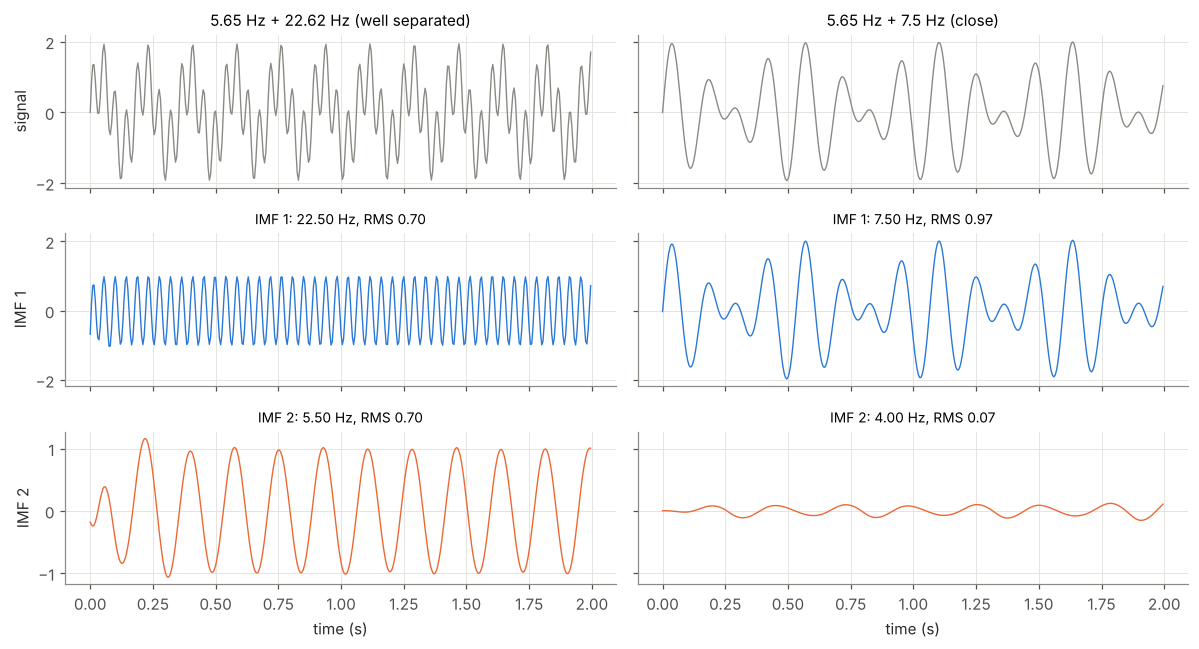

In [4]:
t_short = np.arange(0, 2, 1 / FS)   # 2 s, no noise
cases = {
    "5.65 Hz + 22.62 Hz (well separated)": (F1, F2),
    "5.65 Hz + 7.5 Hz (close)": (F1, 7.5),
}

fig, axes = plt.subplots(3, 2, figsize=(11, 6), sharex=True, sharey="row")
for col, (title, (fa, fb)) in enumerate(cases.items()):
    x_case = np.sin(2 * np.pi * fa * t_short) + np.sin(2 * np.pi * fb * t_short)
    emd_case = EMD()
    emd_case.emd(x_case, t_short)
    imfs_case, _ = emd_case.get_imfs_and_residue()
    axes[0, col].plot(t_short, x_case, color=COLOR_SIGNAL, linewidth=0.9)
    axes[0, col].set_title(title, fontsize=10)
    for row in (1, 2):
        imf = imfs_case[row - 1]
        axes[row, col].plot(t_short, imf, color=COLOR_1 if row == 1 else COLOR_2, linewidth=0.9)
        axes[row, col].set_title(f"IMF {row}: {dominant_frequency(imf, FS):.2f} Hz, "
                                 f"RMS {np.sqrt(np.mean(imf**2)):.2f}", fontsize=9)
for col in (0, 1):
    axes[2, col].set_xlabel("time (s)")
for row, label in enumerate(["signal", "IMF 1", "IMF 2"]):
    axes[row, 0].set_ylabel(label)
fig.tight_layout()
plt.show()

**Interpretación.** Con 5.65 y 22.62 Hz (izquierda) cada frecuencia queda en su propia IMF, con la misma energía (RMS 0.70 cada una). Con 5.65 y 7.5 Hz (derecha) la IMF 1 es prácticamente toda la señal, con batido (RMS 0.97), y la IMF 2 casi no tiene energía (RMS 0.07): la EMD no separó las dos frecuencias.

Variantes que lo mitigan: **EEMD** y **CEEMDAN**, que agregan ruido controlado a la señal, la descomponen muchas veces y promedian; y la **VMD** (*Variational Mode Decomposition*), que descompone de otra forma (resuelve un problema de optimización para encontrar modos de banda estrecha).

### Resumen

| Fortalezas | Debilidades |
|---|---|
| Adaptativa: no necesita elegir una base | Mezcla de modos con frecuencias cercanas |
| Sirve para señales que cambian en el tiempo | Efectos de borde |
| No requiere conocer las frecuencias de antemano (a diferencia del filtro pasabanda) | Sensible al ruido |
| | Sin fundamento matemático cerrado (es un algoritmo) |

**Relación y literatura:** EMD + transformada de Hilbert = **transformada de Hilbert-Huang (HHT)**. Malekjafarian y OBrien (2017) la usan para aislar la componente del modo antes de aplicar Hilbert ([sección 2.1](#transformada-de-hilbert)).

<a id="envolvente-de-amplitud"></a>
# 2. Envolvente de amplitud / amplitud instantánea

Métodos que calculan, en cada instante, la amplitud de una oscilación (su envolvente), sin las subidas y bajadas propias de cada ciclo.

<a id="transformada-de-hilbert"></a>
## 2.1 Transformada de Hilbert

### Para qué sirve

La transformada de Hilbert da la **amplitud de una vibración en cada instante** (la envolvente). La FFT no lo hace, porque promedia todo el registro: dice qué frecuencias hay, pero no cómo cambia su amplitud en el tiempo. En puentes interesa porque, cuando un vehículo cruza, la amplitud del modo cambia con la posición del vehículo, y esa variación refleja la **forma modal**.

### La idea: copia desfasada 90° y envolvente

La transformada genera una **copia de la señal desfasada 90°**, $\mathcal{H}[x(t)]$. Donde una de las dos pasa por cero, la otra está en su máximo, así que juntas siempre "ven" la amplitud. Combinándolas sale la envolvente:

$$
A(t) = \sqrt{x(t)^2 + \mathcal{H}[x(t)]^2}
$$

- $A(t)$: amplitud instantánea o envolvente.
- $x(t)$: señal medida.
- $\mathcal{H}[x(t)]$: transformada de Hilbert, la señal desfasada 90°.

En palabras: la raíz de la señal al cuadrado más su versión desfasada al cuadrado. Por ejemplo, para $x = a\cos(\omega t)$ la copia es $a\sin(\omega t)$ y $A = \sqrt{a^2\cos^2 + a^2\sin^2} = a$.

Ejemplo: un vehículo cruza un puente de $L = 15$ m a $v = 2$ m/s; la componente del modo 1 ($f_1 = 5.65$ Hz) es $x(t) = \sin(\pi v t / L)\cos(2\pi f_1 t)$, muestreada a $f_s = 200$ Hz.

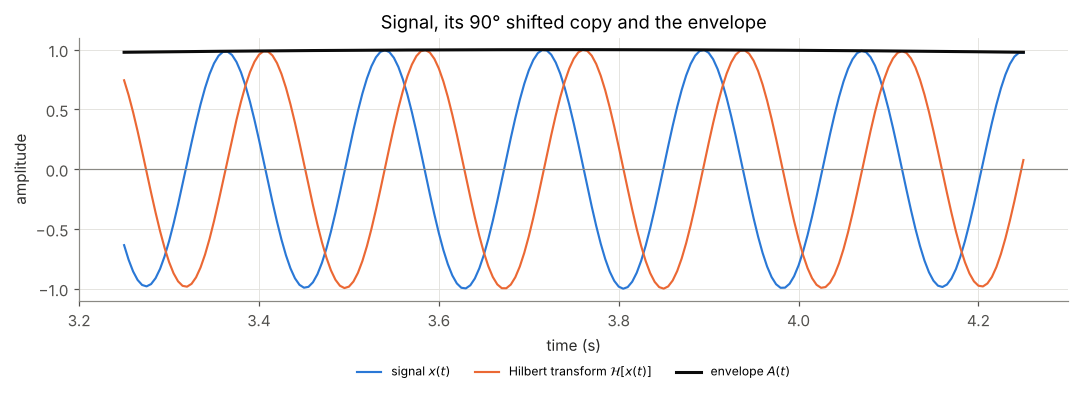

In [5]:
# Mode 1 component of the crossing (shared parameters from the setup cell)
x_ideal = phi_1 * np.cos(2 * np.pi * F1 * t)

z = hilbert(x_ideal)              # analytic signal x + j H[x]
hilbert_x = np.imag(z)            # H[x(t)], the 90° shifted copy
envelope_ideal = np.abs(z)        # A(t) = sqrt(x^2 + H[x]^2)

window = (t >= 3.25) & (t <= 4.25)  # zoom into ~1 s around midspan
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t[window], x_ideal[window], color=COLOR_1, label="signal $x(t)$")
ax.plot(t[window], hilbert_x[window], color=COLOR_2, label=r"Hilbert transform $\mathcal{H}[x(t)]$")
ax.plot(t[window], envelope_ideal[window], color=COLOR_TRUE, linewidth=2, label="envelope $A(t)$")
ax.axhline(0, color=COLOR_SIGNAL, linewidth=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("Signal, its 90° shifted copy and the envelope")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** Donde la señal azul cruza el cero, la naranja está en un pico, y viceversa. La envolvente (negra) pasa por encima de ambas sin oscilar: es la amplitud en cada instante.

### Requisito: una sola componente

No hace falta una senoidal pura: la amplitud puede variar, siempre que cambie mucho más lento que la oscilación. Pero la señal debe tener **una sola frecuencia dominante**. Si mezcla varias, la envolvente sale ondulada y no significa nada.

Por eso, antes de aplicar Hilbert:

- se **quita la media** de la señal;
- se **aísla la componente**: con un **filtro pasabanda** (si se conoce la frecuencia) o con una descomposición como la [**EMD**](#emd) ([sección 1.1](#emd); EMD + Hilbert = transformada de Hilbert-Huang, **HHT**).

Ejemplo: señal con el modo 1 (5.65 Hz), el modo 2 (22.62 Hz, forma $\sin(2\pi x/L)$, menor amplitud) y ruido.

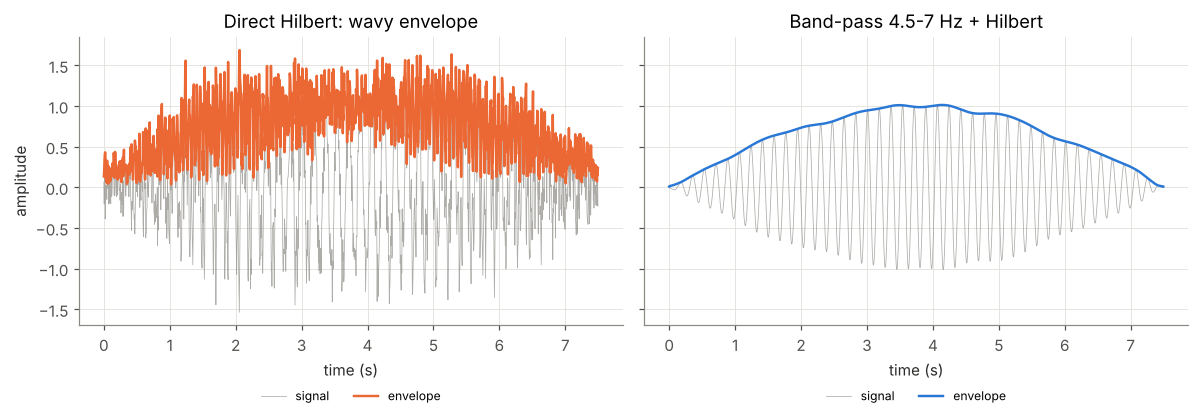

In [6]:
rng = np.random.default_rng(42)   # fixed seed for the noise

x_mode_2 = 0.5 * phi_2 * np.cos(2 * np.pi * F2 * t)
noise = 0.2 * rng.standard_normal(t.size)
x_measured = x_ideal + x_mode_2 + noise
x_measured = x_measured - x_measured.mean()   # remove the mean

# (a) Hilbert applied directly
envelope_direct = np.abs(hilbert(x_measured))

# (b) Band-pass 4.5-7 Hz (4th-order Butterworth, zero phase), then Hilbert
sos = butter(4, [4.5, 7.0], btype="band", fs=FS, output="sos")
x_filtered = sosfiltfilt(sos, x_measured)
envelope_filtered = np.abs(hilbert(x_filtered))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, x, env, color, title in [
    (axes[0], x_measured, envelope_direct, COLOR_2, "Direct Hilbert: wavy envelope"),
    (axes[1], x_filtered, envelope_filtered, COLOR_1, "Band-pass 4.5-7 Hz + Hilbert"),
]:
    ax.plot(t, x, color=COLOR_SIGNAL, linewidth=0.5, alpha=0.7, label="signal")
    ax.plot(t, env, color=color, linewidth=1.6, label="envelope")
    ax.set_title(title)
    ax.set_xlabel("time (s)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)
axes[0].set_ylabel("amplitude")
fig.tight_layout()
plt.show()

**Interpretación.** Aplicada directo, la envolvente sube y baja rápido: el modo 2 y el ruido se suman y se restan con el modo 1, y la curva no representa nada físico. Después del pasabanda queda solo el modo 1 y la envolvente es suave.

### Aplicación a puentes

Al graficar la envolvente contra la **posición del vehículo** ($x = vt$) se obtiene la forma del modo. Dos puntos a tener en cuenta:

- La envolvente es el **valor absoluto**, sin signo: en el segundo modo, que es positivo en una mitad del vano y negativo en la otra, daría $|\phi_2|$ y no se distingue qué lado sube y cuál baja.
- Los **extremos se distorsionan** (efecto de borde), por lo que los primeros y últimos ciclos no se interpretan.

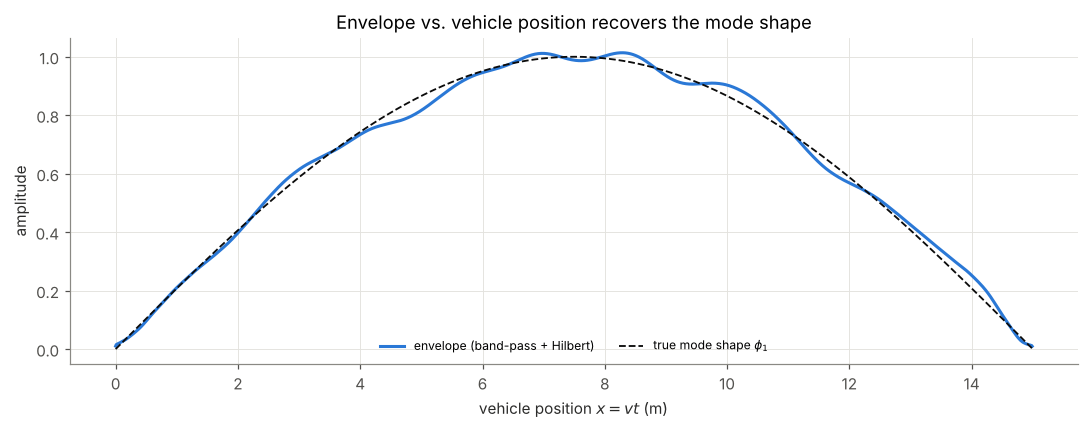

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(position, envelope_filtered, color=COLOR_1, linewidth=2, label="envelope (band-pass + Hilbert)")
ax.plot(position, phi_1, "--", color=COLOR_TRUE, linewidth=1.2, label=r"true mode shape $\phi_1$")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("amplitude")
ax.set_title("Envelope vs. vehicle position recovers the mode shape")
ax.legend(loc="lower center", ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** La envolvente sigue la forma modal real; las pequeñas ondulaciones vienen del ruido que cae dentro de la banda del filtro. En este ejemplo los extremos casi no se distorsionan porque la señal empieza y termina con amplitud cero; con señales reales, que no empiezan ni terminan en cero, el efecto de borde sí se nota.

**En la literatura:** Malekjafarian y OBrien (2017) la usan así: aplican la HHT a las aceleraciones de los ejes de un camión con remolques que lleva un excitador, para estimar las formas modales del puente. Su validación es solo en simulación.

### Resumen

| Fortalezas | Debilidades |
|---|---|
| Da la amplitud en cada instante | Exige una sola componente (filtrado o descomposición previa) |
| Sirve para señales que cambian en el tiempo | Sensible al ruido |
| Simple y rápida | Efectos de borde |
| | Pierde el signo de la forma modal |